# 10장 파일 및 예외처리

In [2]:
y = 2
print(y)

z = 0
print(z)

w = z / y
print(w)

if z != 0:
    q = y / z
    print(q)
else:
    print("z가 0이라 나눌 수 없습니다.")

2
0
0.0
z가 0이라 나눌 수 없습니다.


# 학습 목표
- 텍스트 파일 읽고 쓰기를 살펴본다.
- 이진 파일 읽고 쓰기를 살펴본다.
- 정규식을 사용하는 방법을 살펴본다.
- CSV 파일 읽고 쓰기를 살펴본다.
- 예외를 처리하는 방법을 살펴본다.

# 파일의 기초
- 프로그램에서 만든 데이터를 영구히 저장하고자 한다면 하드 디스크에 파일 형태로 저장하여야 한다.

# 파일의 개념
- 파일은 보조기억장치(영구저장장치)에 기록된 논리적인 정보 단위이다.
    - 파일 안에 저장된 정보는 바이트 단위로 순차적으로 기록되어 있다.
    - 첫 번쨰 바이트의 위치를 오프셋(offset) 0라고 하고 1씩 증가한다.
    - 파일을 읽고 쓰려면 먼저 파일을 열어야 한다.
    - 열린 파일 포인터는 최초에 파일을 열 때는 0을 가리키며 접근한 바이트 수만큼 증가한다.
    - 파일을 접근할 때느 열린 파일 포인터의 위치부터 읽거나 쓴다.
    - 파일의 끝을 EOF (End of File) 라고 한다.

# 파일의 논리적인 구조
- 파일:
    - 바이트들이 순차적으로 저장되어 있고 맨 끝에는 EOF(end-of-file) 마커가 있다.
    - 파일 포안터(offset): 각 바이트는 첫 바이트 0, 두번째 바이트는 1 등으로 offset이 부여된다.
- 파일의 종류
    - 텍스트 파일 : 각 바이트가 문자로 구성된 파일 (메모장으로 열었을 때 눈으로 글자 확인 가능)
        - 한글 유니코드느 각 문자가 2B 로 구성되어 있으며 저장될 때는 UTF-8 등으로 인코딩되어 저장되고 읽을 때는 다시 디코딩되어 읽힘 (영문자는 1B로 구성되어 영향 없음
    - 이진 파일 : 이진수의 바이트 배열이 저장된 파일 (메모장으로 열면 글자가 꺠져 보임)

# 디렉토리(폴더)의 개념
- 폴더(디렉토리)
    - 폴더는 파일이나 서브폴더들을 가질 수 있다.
    - 폴더는 일반적으로 디렉토리라고 한다.
    - 루트디렉토리느 '/' 윈도우에서는 '\'이다.
    - 드라이브(혹은 볼륨)는 윈도우에서 별도의 루트디렉토리를 가진 파일 시스템을 의미한다. (C:, D: 등)
    - 부모펄더와 자식폴더 사이에는 '/' 문자로 구분한다. C:\user\song\PP2-2026


# 경로(Path) 개념
- 경로
    - 절대경로: C:\user\song\PP2-2026\chap10\input.txt
    - 현재경로: 현재 프로그램이 실행 중인 절대경로
    - 상대경로: .\chap10\input.txt 처럼 현재경로를 기준으로 한 경로
        - “.” : 현재 디렉토리 ( “C:\user\song\PP2-2026” 처럼 현재 실행 중인 python 파일 폴더)
        - “..” : 부모 디렉토리 ( “../chap10/input.txt)

# 한 줄(line)을 단어로 분리하기 : str.split()
- str.strip(<구문문자>) : <구문문자>를 안 줄 경우에는 공백문자 (스페이스, 탭 등)
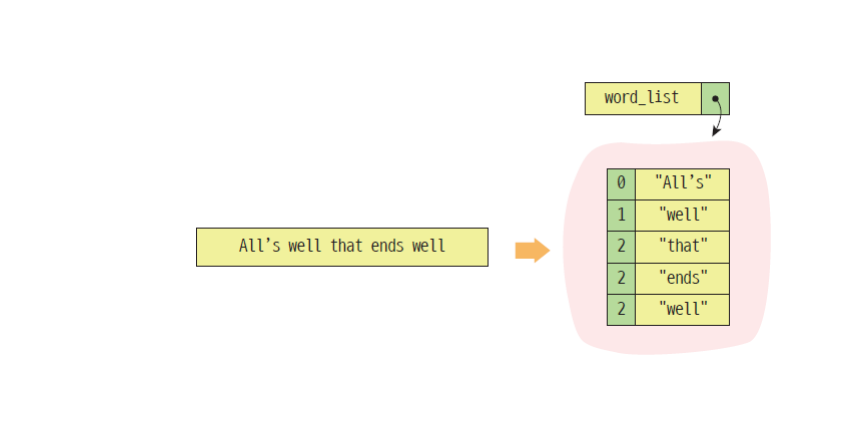

# 문자 엔코딩
- 최근에는 세계의 모든 문자를 나타낼 수 있는 유니코드가 사용된다.
- 유니코드 중에서 가장 많이 사용되는 인코딩은 UTF-8이다. UTF-8에서는 각 문자를 1개에서 4개의 바이트로 가변적으로 인코딩한다.

- infile = open("input.txt", "r", "endcoding="utf-8")

# 이진 파일
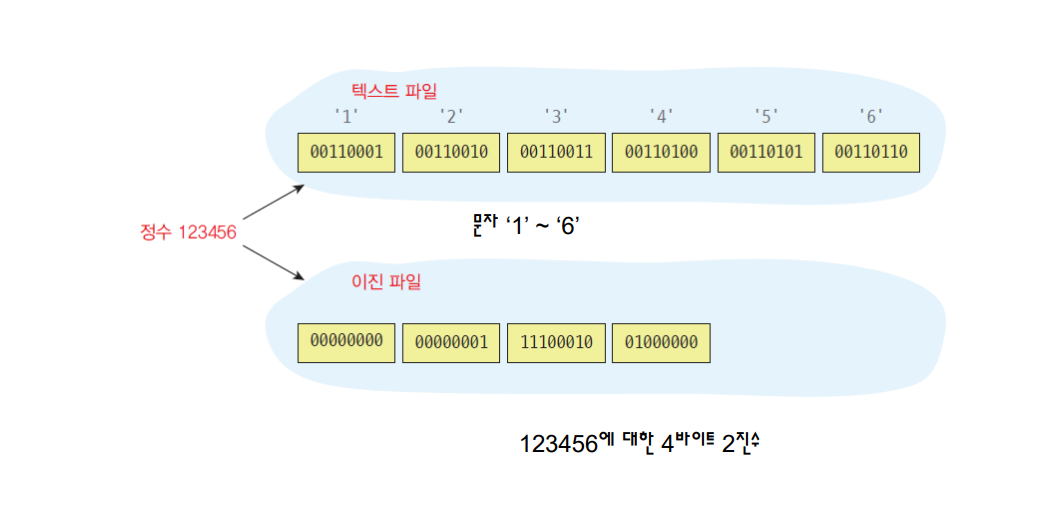

# 순차접근과 임의접근 
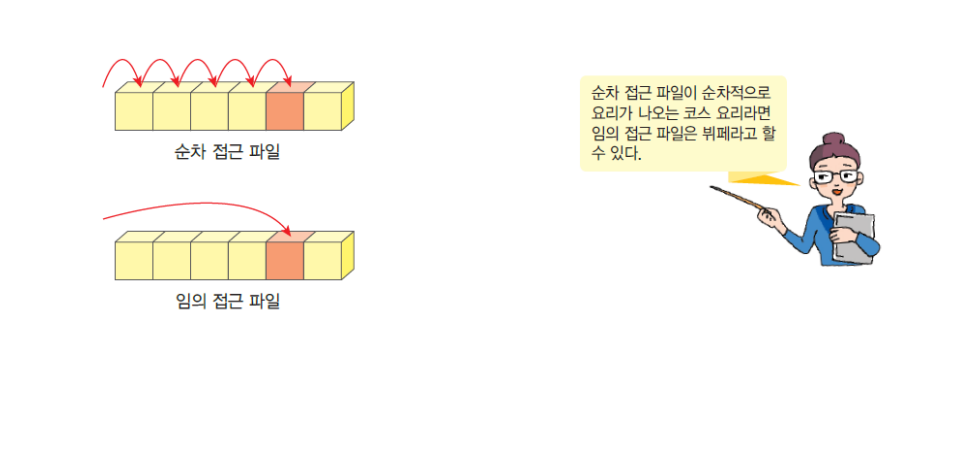

# 임의접근의 권리
- 파일 포인터는 읽기와 쓰기 동작이 현재 어떤 위치에서 이루어지는 지를 나타낸다.
    - 막 열었을 때 파일포인터는 0을 가리킨다.
    - 읽고 쓸 때마다 읽은 바이트 수만큼 파일 포인터는 증가
    - 다 읽었을 때는 EOF를 가리킴
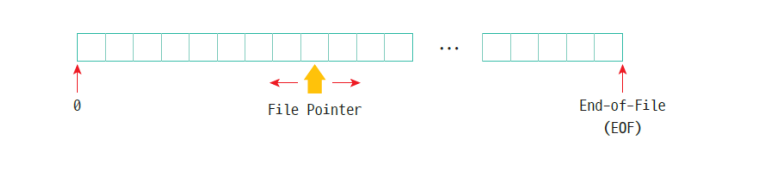
- 임의로 파일포인터 위치를 바꿀 수 있다.
    - file.seek(오프셋, 기준위치) → 기준위치로부터 offset 만큼 이동
    - file.tell() → 현재 위치 반환
    - 기준위치 (예 현재 파일 포인터 위치가 100이라고 하고 파일크기가 1000일 때)
        - 0 : 파일 시작 기준 - seek(10,0) : 절대 위치 10
        - 1 : 현재 위치 기준 – seek(10,1) : 현재 위치 100 + 5 = 105
        - 2 : 파일 끝 기준 – seek(-10, 2) : 끝에서 1000 -10 = 990


# 객체 파일 저장 및 복원
- pickle 모듈의 dump()와 load() 메소드를 사용하면 객체데이터를 쓰고 읽을 수 있다.
- 리스트, 튜플, 딕셔너리, 셋 등 파이썬의 기본 데이터 타입 가능
- 이진수로 저장됨
- 다시 거꾸로 복원도 가능
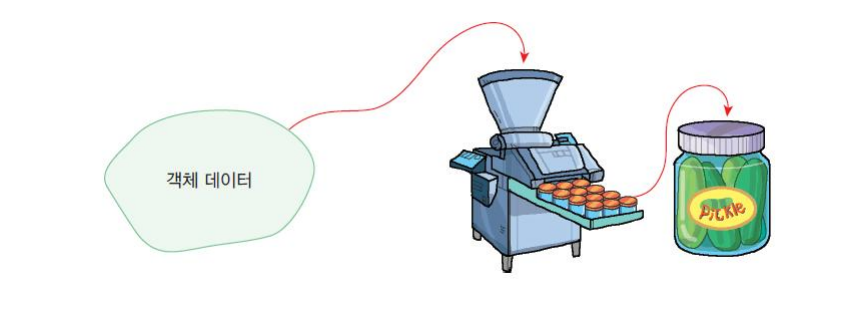

# 정규식
- 정규식(regular expression)이란 특정한 규칙을 가지고 있는 문자열들을 메타 문자를 이용하여 표현하
는 수식이다.
- re 모듈을 사용 : re.search()
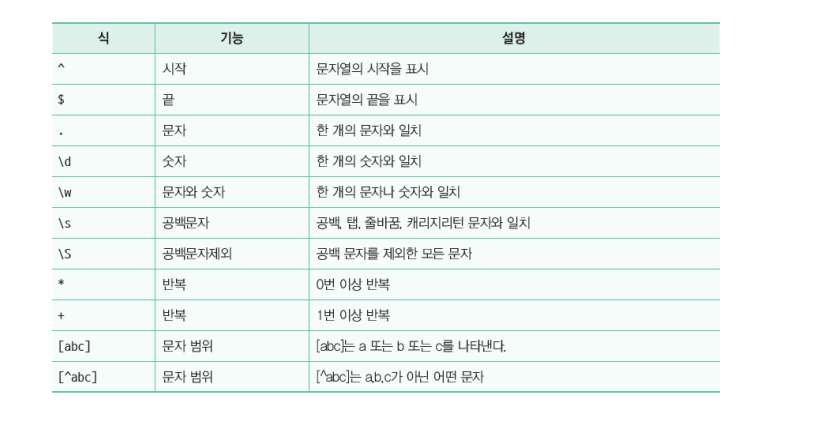

# 정규식에서 점과 별표의 의미
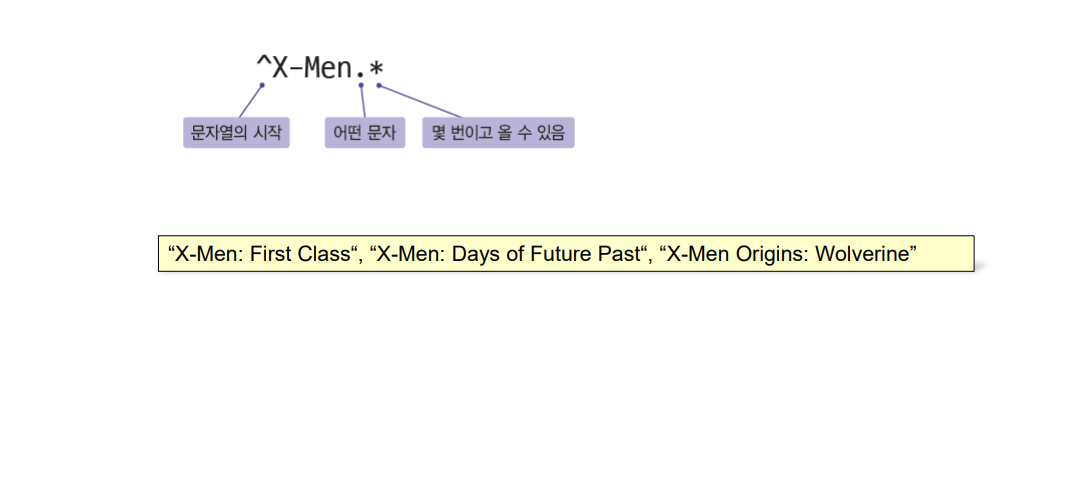

# 예외처리
- 사용자들은 잘못된 데이터를 입력할 수도 있고, 우리가 오픈하고자 하는 파일이 컴퓨터에 존재하지 않
을 수도 있으며 인터넷이 다운될 수도 있다.
- 0으로 나누기, 잘못된 주소를 접근, 파일 접근 시 오류 (파일없음, 권한 없음 등)
- 오류가 발생했을 때 오류를 사용자에게 알려주고 모든 데이터를 저장하게 한 후에 사용자가 우아하게
(gracefully) 프로그램을 종료할 수 있도록 하는 것이 바람직
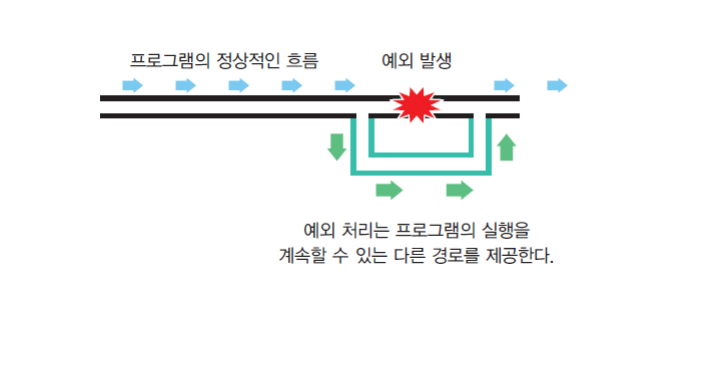

 # 작업폴더 python 파일 실행하는 위치

In [34]:
with open("file.txt", "r", encoding="utf-8") as f:
   # for line in f:
   #     print(line.strip())     
    line = f.readline().strip()
    while line != "":
        print(line)
        line = f.readline().strip()
        
    eline = f.readline().strip()
    print(eline)
    print(f.tell())
    
    f.seek(0,0)
    eline = f.readline().strip()
    print(eline)
    print(f.tell())

홍길동
고길동

20
홍길동
11
